# Pit strategy (exploratory)

These analyses are descriptive and exploratory. They were not pre-registered. The 2025 data had already been seen when the plan was written, and the plan (`EXPLORATORY_ANALYSIS_PLAN.md`) was written before any of these results was computed.

What a team planned before a race is not public. This analysis never claims to know a plan or an intention. A reference strategy is defined from what the field did under green-flag running, and each tyre change is tagged with the circumstances the data shows. Sentences about motive say "consistent with".

The strategy rules were amended once after the results were first computed. A stint number change with pit flags set, where the same compound continued and the tyre age rose by exactly 1, is no longer counted as a tyre change. It is listed as SAME_TYRE_CONTINUATION. The reason, the counts and the before and after values are in `EXPLORATORY_ANALYSIS_PLAN_AMENDMENT_1.md` and `results/strategy_fix_comparison.csv`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as cfg
import expansion_config as xc
import f1deg as F
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
COL = {"SOFT": "#d93025", "MEDIUM": "#c79a00", "HARD": "#4a4f57"}

from pathlib import Path
base = Path("results/strategy")
ch = pd.read_csv(base / "changes.csv")
ref = pd.read_csv(base / "reference.csv")
rs = pd.read_csv(base / "race_summary.csv")
dr = pd.read_csv(base / "drivers.csv")
ss = pd.read_csv(base / "season_summary.csv")
ss["season"] = ss["season"].astype(str)
CIRCS = ["RED_FLAG", "WEATHER_TO_WET", "WEATHER_TO_DRY", "WET_TO_WET", "SAFETY_CAR", "VIRTUAL_SAFETY_CAR", "COVER", "UNDERCUT_ATTEMPT",
         "ON_REFERENCE", "EXTRA_STOP", "EARLIER_THAN_REFERENCE", "LATER_THAN_REFERENCE", "UNFLAGGED_CHANGE", "UNKNOWN_COMPOUND", "NO_REFERENCE"]
print("tyre changes:", len(ch), " races:", len(rs), " tyre-data-incomplete races:", int(rs["incomplete"].sum()))
print(rs[rs["incomplete"]][["season", "event", "tyre_changes"]].to_string(index=False))
print("renumbering artifacts:", int(ref["artifacts"].sum()), " pit lane passes without a tyre change:", int(ref["pit_passes"].sum()))

tyre changes: 3110  races: 92  tyre-data-incomplete races: 3
 season               event  tyre_changes
   2022 Austrian Grand Prix            42
   2025    Miami Grand Prix            18
   2025  Belgian Grand Prix            26
renumbering artifacts: 0  pit lane passes without a tyre change: 20


## What this can and cannot say
A race is `tyre_data_incomplete` when more than 5 percent of its rows lack a stint or a compound. Such races are shown but left out of every summary below.

## Reference strategies
The reference is what most completing drivers did under green: the most common number of tyre changes, the median in-lap of each stop, and the most common compound sequence. It is not a team plan.

In [2]:
r = ref[~ref["incomplete"]]
print(r.groupby("season")["reference_stops"].value_counts().unstack(fill_value=0).to_string())
print()
print(r[r["season"] == 2025][["event", "reference_stops", "reference_laps", "reference_sequences"]].to_string(index=False))

reference_stops   1   2  3  4
season                       
2022              8   9  4  0
2023              7  11  3  1
2024             12  12  0  0
2025             11  10  1  0

                    event  reference_stops reference_laps                                                                                                                      reference_sequences
    Australian Grand Prix                2              ;                                                                                                           INTERMEDIATE>HARD>INTERMEDIATE
       Chinese Grand Prix                1           14.5                                                                                                                              MEDIUM>HARD
      Japanese Grand Prix                1             24                                                                                                                              MEDIUM>HARD
       Bahrain Grand Prix              

## Primary circumstance of tyre changes
Every tyre change gets exactly one primary circumstance, the first that applies in the order fixed in the plan.

season                  2022  2023  2024  2025   ALL
group                                               
RED_FLAG                 6.4  10.0   5.5   0.0   5.7
WEATHER_TO_WET           0.0   6.4   2.7   3.1   3.1
WEATHER_TO_DRY           7.1   1.8   4.9   4.9   4.6
WET_TO_WET               3.8   0.4   0.9   0.0   1.3
SAFETY_CAR              14.0  10.7   9.8  15.0  12.2
VIRTUAL_SAFETY_CAR       6.8   4.3   3.0   3.8   4.5
COVER                    5.6   6.0   6.6   7.5   6.4
UNDERCUT_ATTEMPT        11.2  16.3  17.9  20.6  16.4
ON_REFERENCE            23.5  20.7  21.5  19.3  21.3
EXTRA_STOP               4.2   3.0   7.7   4.3   4.8
EARLIER_THAN_REFERENCE   8.4  10.1   8.9   9.1   9.2
LATER_THAN_REFERENCE     8.4   9.7  10.2  11.6  10.0
UNFLAGGED_CHANGE         0.0   0.0   0.0   0.0   0.0
UNKNOWN_COMPOUND         0.0   0.0   0.0   0.0   0.0
NO_REFERENCE             0.5   0.7   0.3   0.9   0.6


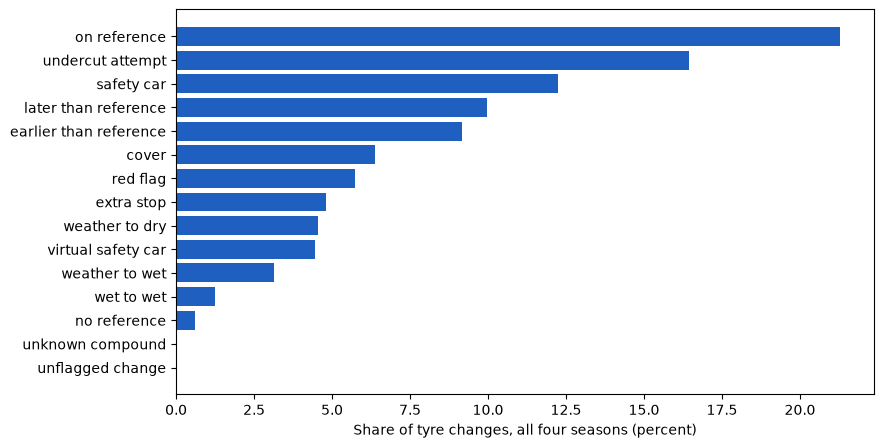

In [3]:
sh = ss[(ss["metric"] == "share_of_changes")].pivot(index="group", columns="season", values="value").reindex(CIRCS)
print((100 * sh).round(1).to_string())
fig, ax = plt.subplots(figsize=(9, 5))
order = sh["ALL"].sort_values().index
ax.barh(range(len(order)), 100 * sh.loc[order, "ALL"], color="#1f5fbf")
ax.set_yticks(range(len(order))); ax.set_yticklabels([o.replace("_", " ").lower() for o in order])
ax.set_xlabel("Share of tyre changes, all four seasons (percent)")
fig.savefig("Images/strategy_circumstances.png", dpi=150, bbox_inches="tight")
plt.show()

## Stop cost under green, safety car and virtual safety car
The cost of a stop is the in-lap plus out-lap time minus the median of the same two laps for drivers who stayed out under the same conditions. Intervals come from resampling races. Pit stops only.

season              group                         metric  value     lo     hi    n  n_races  note
  2022              green             median_stop_cost_s 22.783 21.755 23.270  472     21.0   NaN
  2022         SAFETY_CAR             median_stop_cost_s 15.784 14.446 20.972   74     13.0   NaN
  2022 VIRTUAL_SAFETY_CAR             median_stop_cost_s 13.719 12.088 20.656   51     10.0   NaN
  2022         SAFETY_CAR green_minus_median_stop_cost_s  6.999  1.836  8.239  546     21.0   NaN
  2022 VIRTUAL_SAFETY_CAR green_minus_median_stop_cost_s  9.064  1.793 10.809  523     21.0   NaN
  2023              green             median_stop_cost_s 22.762 21.602 24.316  581     22.0   NaN
  2023         SAFETY_CAR             median_stop_cost_s 15.110 10.939 21.834   82     10.0   NaN
  2023 VIRTUAL_SAFETY_CAR             median_stop_cost_s 19.586 13.916 30.339   35      6.0   NaN
  2023         SAFETY_CAR green_minus_median_stop_cost_s  7.651  0.581 12.275  663     22.0   NaN
  2023 VIRTUAL_SAFET

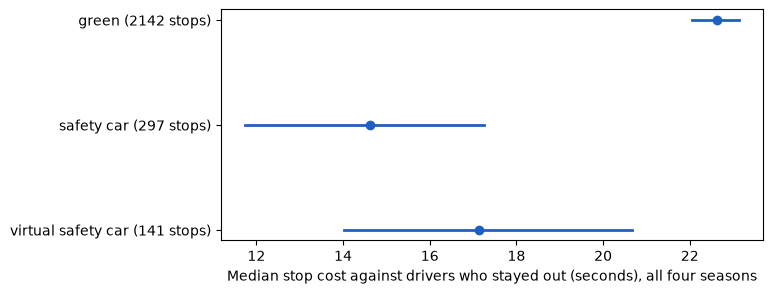

In [4]:
cost = ss[ss["metric"].isin(["median_stop_cost_s", "green_minus_median_stop_cost_s"])]
print(cost[["season", "group", "metric", "value", "lo", "hi", "n", "n_races", "note"]].round(3).to_string(index=False))
a = ss[(ss["season"] == "ALL") & (ss["metric"] == "median_stop_cost_s")].set_index("group").loc[["green", "SAFETY_CAR", "VIRTUAL_SAFETY_CAR"]]
fig, ax = plt.subplots(figsize=(7, 3))
for i, (g, r) in enumerate(a.iterrows()):
    ax.plot([r["lo"], r["hi"]], [i, i], color="#1f5fbf", lw=2)
    ax.plot(r["value"], i, "o", color="#1f5fbf")
ax.set_yticks(range(3)); ax.set_yticklabels([g.replace("_", " ").lower() + f" ({int(a.loc[g, 'n'])} stops)" for g in a.index]); ax.invert_yaxis()
ax.set_xlabel("Median stop cost against drivers who stayed out (seconds), all four seasons")
fig.savefig("Images/strategy_stop_cost.png", dpi=150, bbox_inches="tight")
plt.show()

## Undercut outcomes
A tyre change is tagged UNDERCUT_ATTEMPT when the car ahead is within the gap limit and has not stopped. The outcome compares positions after that car stops within the response window.

In [5]:
u = ss[ss["metric"].isin(["undercut_count", "success_share_of_resolved"])]
print(u[["season", "group", "metric", "value", "n"]].round(3).to_string(index=False))

season        group                    metric   value   n
  2022    SUCCEEDED            undercut_count  22.000  22
  2022       FAILED            undercut_count  21.000  21
  2022 NOT_RESOLVED            undercut_count  51.000  51
  2022     undercut success_share_of_resolved   0.512  43
  2023    SUCCEEDED            undercut_count  37.000  37
  2023       FAILED            undercut_count  23.000  23
  2023 NOT_RESOLVED            undercut_count  90.000  90
  2023     undercut success_share_of_resolved   0.617  60
  2024    SUCCEEDED            undercut_count  39.000  39
  2024       FAILED            undercut_count  22.000  22
  2024 NOT_RESOLVED            undercut_count  94.000  94
  2024     undercut success_share_of_resolved   0.639  61
  2025    SUCCEEDED            undercut_count  19.000  19
  2025       FAILED            undercut_count  20.000  20
  2025 NOT_RESOLVED            undercut_count 109.000 109
  2025     undercut success_share_of_resolved   0.487  39
   ALL    SUCC

## Races with the most drivers who differed from the reference

 season                     event  share_differs common_primary_among_differing
   2024  Saudi Arabian Grand Prix            1.0                     SAFETY_CAR
   2025          Dutch Grand Prix            1.0                     SAFETY_CAR
   2024         Monaco Grand Prix            1.0                       RED_FLAG
   2024       Canadian Grand Prix            1.0                     SAFETY_CAR
   2023      São Paulo Grand Prix            1.0                       RED_FLAG
   2024      São Paulo Grand Prix            1.0                       RED_FLAG
   2025     Australian Grand Prix            1.0                 WEATHER_TO_DRY
   2023      Singapore Grand Prix            1.0                     SAFETY_CAR
   2023          Dutch Grand Prix            1.0                       RED_FLAG
   2025 Emilia Romagna Grand Prix            1.0             VIRTUAL_SAFETY_CAR
season  value    n  n_races
  2022  0.788  283     21.0
  2023  0.799  311     22.0
  2024  0.740  319     24.0
  2025  

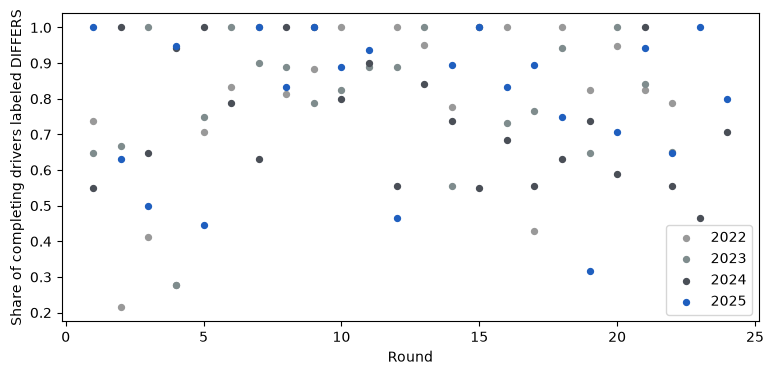

In [6]:
v = rs[~rs["incomplete"]].sort_values("share_differs", ascending=False)
print(v[["season", "event", "share_differs", "common_primary_among_differing"]].head(10).round(3).to_string(index=False))
sd = ss[(ss["metric"] == "share_differs")][["season", "value", "n", "n_races"]]
print(sd.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 4))
for y, c in zip([2022, 2023, 2024, 2025], ["#999999", "#7f8c8d", "#4a4f57", "#1f5fbf"]):
    z = v[v["season"] == y]
    ax.scatter(z["round"], z["share_differs"], color=c, label=str(y), s=18)
ax.set_xlabel("Round"); ax.set_ylabel("Share of completing drivers labeled DIFFERS"); ax.legend()
fig.savefig("Images/strategy_by_race.png", dpi=150, bbox_inches="tight")
plt.show()

## Wet races
Wet races are kept in this module. Their changes between dry and wet compounds are tagged by rule.

In [7]:
w = pd.read_csv("results/races.csv")
wet_ids = [(2025, int(r)) for r in w[w["status"] == "wet"]["Round"]]
for y in [2022, 2023, 2024]:
    rr = pd.read_csv(f"results/replication/{y}_races.csv")
    wet_ids += [(y, int(r)) for r in rr[rr["status"] == "wet"]["Round"]]
sub = ch[[ (a, b) in wet_ids for a, b in zip(ch["season"], ch["round"])]]
print(sub.groupby(["season", "event"])["primary"].value_counts().unstack(fill_value=0).to_string())

primary                           COVER  EARLIER_THAN_REFERENCE  EXTRA_STOP  LATER_THAN_REFERENCE  NO_REFERENCE  ON_REFERENCE  RED_FLAG  SAFETY_CAR  UNDERCUT_ATTEMPT  VIRTUAL_SAFETY_CAR  WEATHER_TO_DRY  WEATHER_TO_WET  WET_TO_WET
season event                                                                                                                                                                                                                         
2022   Emilia Romagna Grand Prix      0                       0           5                     0             0             0         0           0                 1                   0              18               0           0
       Japanese Grand Prix            0                       0           1                     0             0             0        19           0                 4                   0               0               0          18
       Monaco Grand Prix              1                       0           3     

## Stint chart of one race
The race below is picked by rule: the largest share of completing drivers labeled DIFFERS among races not flagged tyre_data_incomplete, over all four seasons. Ties go to the earliest season, then the earliest round.

picked: 2022 Monaco Grand Prix share DIFFERS: 1.0


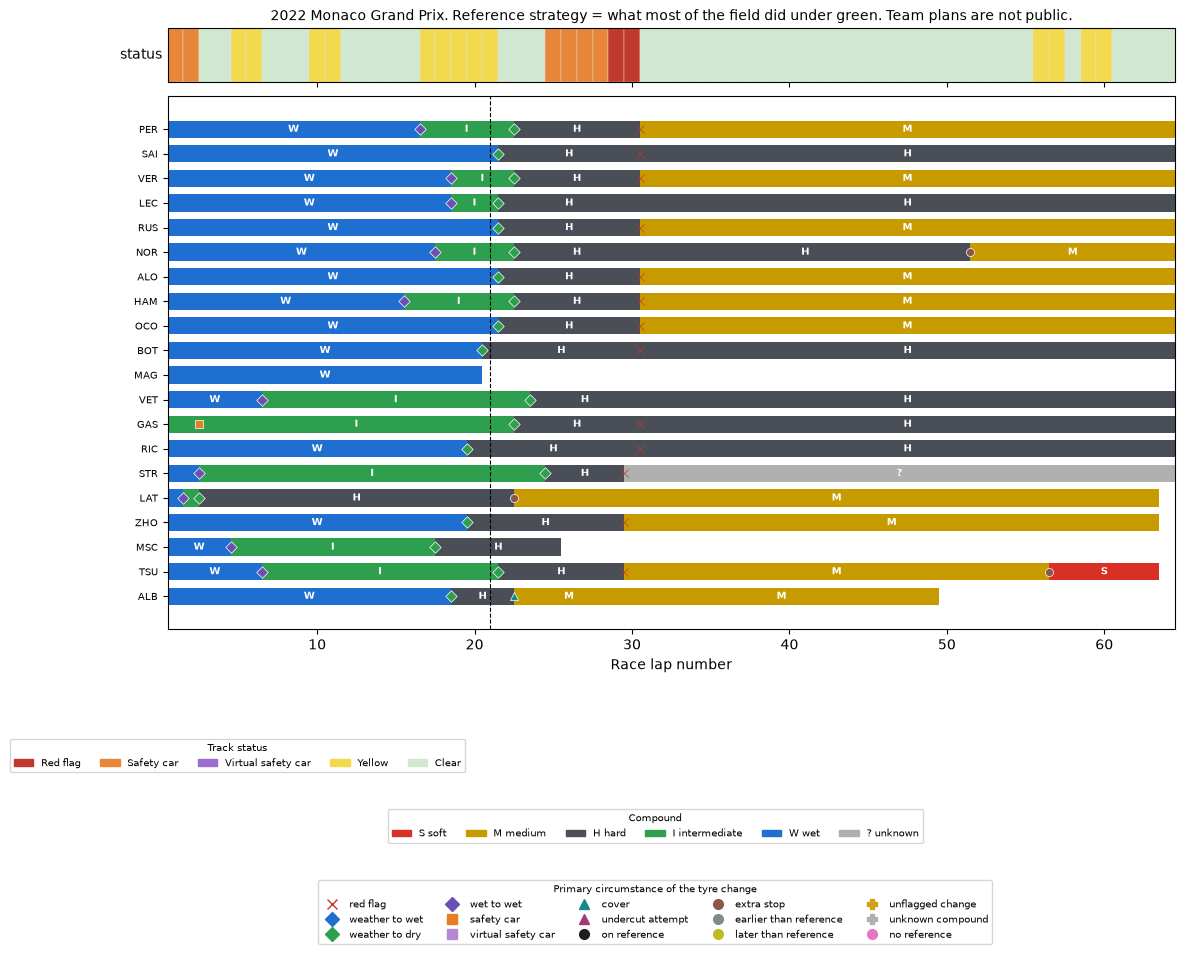

In [8]:
tl = pd.read_csv(base / "status_timeline.csv", dtype={"statuses": str})
cand = rs[~rs["incomplete"]].sort_values(["share_differs", "season", "round"], ascending=[False, True, True])
top = cand.iloc[0]
season, rnd = int(top["season"]), int(top["round"])
print("picked:", season, top["event"], "share DIFFERS:", round(float(top["share_differs"]), 3))
laps = pd.read_csv(f"data/laps_{season}.csv", dtype={"TrackStatus": str})
raw = laps[laps["Round"] == rnd]
u = raw[raw["Stint"].notna() & raw["LapNumber"].notna()].sort_values(["Driver", "LapNumber"])
total = int(raw["LapNumber"].max())
cch = ch[(ch["season"] == season) & (ch["round"] == rnd)]
rr = ref[(ref["season"] == season) & (ref["round"] == rnd)].iloc[0]
ref_laps = [float(v) for v in str(rr["reference_laps"]).split(";") if v not in ("", "nan")] if isinstance(rr["reference_laps"], str) else []
tls = tl[(tl["season"] == season) & (tl["round"] == rnd)].set_index("lap")["statuses"]
STAT = [("5", "Red flag", "#c0392b"), ("4", "Safety car", "#e8863a"), ("6", "Virtual safety car", "#9b6fd0"), ("7", "Virtual safety car", "#9b6fd0"), ("2", "Yellow", "#f2d94e"), ("1", "Clear", "#cfe8cf")]
def scol(s):
    for d, _, c in STAT:
        if isinstance(s, str) and d in s:
            return c
    return "#ffffff"
CMP = {"SOFT": ("#d93025", "S"), "MEDIUM": ("#c79a00", "M"), "HARD": ("#4a4f57", "H"), "INTERMEDIATE": ("#2e9e4f", "I"), "WET": ("#1f6fd1", "W")}
order = []
for drv, g in raw.groupby("Driver"):
    last = g.sort_values("LapNumber").dropna(subset=["Position"]).tail(1)
    order.append((int(last["Position"].iloc[0]) if len(last) else 99, drv))
order = [d for _, d in sorted(order)]
MK = {"RED_FLAG": ("x", "#c0392b"), "WEATHER_TO_WET": ("D", "#1f6fd1"), "WEATHER_TO_DRY": ("D", "#2e9e4f"), "WET_TO_WET": ("D", "#6c4fb3"), "SAFETY_CAR": ("s", "#e67e22"),
      "VIRTUAL_SAFETY_CAR": ("s", "#b48ad6"), "COVER": ("^", "#0f8b8d"), "UNDERCUT_ATTEMPT": ("^", "#a23b72"), "ON_REFERENCE": ("o", "#1c1e21"), "EXTRA_STOP": ("o", "#8c564b"),
      "EARLIER_THAN_REFERENCE": ("o", "#7f8c8d"), "LATER_THAN_REFERENCE": ("o", "#bcbd22"), "UNFLAGGED_CHANGE": ("P", "#d4a017"), "UNKNOWN_COMPOUND": ("P", "#b0b0b0"), "NO_REFERENCE": ("o", "#e377c2")}
fig, (a0, a1) = plt.subplots(2, 1, figsize=(13, 0.28 * len(order) + 2.2), sharex=True, gridspec_kw={"height_ratios": [1, max(4, len(order) * 0.5)], "hspace": 0.05})
for lap in range(1, total + 1):
    a0.add_patch(plt.Rectangle((lap - 0.5, 0), 1, 1, color=scol(tls.get(lap)), ec="#e5e5e0", lw=0.3))
a0.set_ylim(0, 1); a0.set_yticks([]); a0.set_ylabel("status", rotation=0, ha="right", va="center")
a0.set_title(f"{season} {top['event']}. Reference strategy = what most of the field did under green. Team plans are not public.", fontsize=10)
for i, drv in enumerate(order):
    g = u[u["Driver"] == drv]
    for st, s in g.groupby("Stint"):
        comp = s["Compound"].dropna()
        c = comp.iloc[0] if len(comp) else None
        col, ch_ = CMP.get(c, ("#b0b0b0", "?"))
        x0, x1 = s["LapNumber"].min() - 0.5, s["LapNumber"].max() + 0.5
        a1.barh(i, x1 - x0, left=x0, height=0.7, color=col)
        if x1 - x0 > 2:
            a1.text((x0 + x1) / 2, i, ch_, color="white", ha="center", va="center", fontsize=7, fontweight="bold")
    for _, c in cch[cch["driver"] == drv].iterrows():
        m, mc = MK[c["primary"]]
        a1.scatter(c["in_lap"] + 0.5, i, marker=m, s=34, color=mc, edgecolor="white", linewidth=0.5, zorder=3)
for v in ref_laps:
    a1.axvline(v, color="black", ls="--", lw=0.8)
a1.set_yticks(range(len(order))); a1.set_yticklabels(order, fontsize=7); a1.invert_yaxis()
a1.set_xlim(0.5, total + 0.5); a1.set_xlabel("Race lap number")
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
h1 = [Patch(color=c, label=l) for d, l, c in STAT if d != "7"]
h2 = [Patch(color=v[0], label=f"{v[1]} {k.lower()}") for k, v in CMP.items()] + [Patch(color="#b0b0b0", label="? unknown")]
h3 = [Line2D([0], [0], marker=MK[k][0], color="w", markerfacecolor=MK[k][1], markeredgecolor=MK[k][1], markersize=7, label=k.replace("_", " ").lower()) for k in MK]
l1 = fig.legend(handles=h1, loc="lower left", ncol=5, fontsize=7, title="Track status", bbox_to_anchor=(0.0, -0.08), title_fontsize=7)
l2 = fig.legend(handles=h2, loc="lower center", ncol=6, fontsize=7, title="Compound", bbox_to_anchor=(0.5, -0.17), title_fontsize=7)
l3 = fig.legend(handles=h3, loc="lower center", ncol=5, fontsize=7, title="Primary circumstance of the tyre change", bbox_to_anchor=(0.5, -0.30), title_fontsize=7)
fig.savefig("Images/strategy_stint_chart.png", dpi=150, bbox_inches="tight")
plt.show()

The race was picked by rule. Among races that are not flagged tyre_data_incomplete, over all four seasons, it has the largest share of completing drivers labeled DIFFERS. Ties would go to the earliest season, then the earliest round. Dashed lines are the reference laps, markers sit on the in-lap of each tyre change. The cell below prints the generated sentence for every stop of the three drivers whose stops differ most from the reference. Differing is measured as the sum of absolute laps from the reference lap over the driver's stops that have a reference lap, and ties go to the driver code in alphabetical order. The sentences describe circumstances and say what a stop is consistent with. They do not claim an intent.

In [9]:
x = cch[cch["laps_from_ref"].notna()].assign(a=lambda d: d["laps_from_ref"].abs()).groupby("driver")["a"].sum().reset_index()
x = x.sort_values(["a", "driver"], ascending=[False, True]).head(3)
print(x.round(1).to_string(index=False))
for drv in x["driver"]:
    print()
    print(drv)
    for _, c in cch[cch["driver"] == drv].sort_values("stop").iterrows():
        print("  " + c["sentence"])
banned = ["decided", "planned", "wanted", "chose to", "because"]
print()
print("banned words present:", any(w in " ".join(cch["sentence"]).lower() for w in banned))

driver    a
   LAT 20.0
   GAS 19.0
   STR 19.0

LAT
  Stop 1 on lap 1 was 20 laps earlier than the reference lap and came under a safety car, which is consistent with a cheaper stop.
  Stop 2 on lap 2 was with no reference lap defined and came under a safety car, which is consistent with a cheaper stop.
  Stop 3 on lap 22 was an extra stop beyond the reference count and came with no pit lane lap recorded, which is consistent with no pattern this analysis can name.

GAS
  Stop 1 on lap 2 was 19 laps earlier than the reference lap and came under a safety car, which is consistent with a cheaper stop.
  Stop 2 on lap 22 was with no reference lap defined and came with a switch to dry tyres, which is consistent with reacting to the weather.
  Stop 3 on lap 30 was an extra stop beyond the reference count and came under a safety car, which is consistent with a cheaper stop.

STR
  Stop 1 on lap 2 was 19 laps earlier than the reference lap and came under a safety car, which is consistent with 

## Position change over the stop cycle
Places gained between the lap before the stop and a few laps after it. It mixes the stop with everything else that happens in those laps.

In [10]:
pc = ss[(ss["metric"] == "median_position_change") & (ss["season"] == "ALL")][["group", "value", "n"]]
print(pc.round(2).to_string(index=False))

                 group  value   n
              RED_FLAG    0.0 101
        WEATHER_TO_WET    0.0  85
        WEATHER_TO_DRY    0.0 137
            WET_TO_WET   -1.0  36
            SAFETY_CAR    0.0 338
    VIRTUAL_SAFETY_CAR   -1.0 123
                 COVER   -3.0 192
      UNDERCUT_ATTEMPT   -3.0 484
          ON_REFERENCE   -2.0 641
            EXTRA_STOP   -2.0 115
EARLIER_THAN_REFERENCE   -3.0 256
  LATER_THAN_REFERENCE   -3.0 286
      UNFLAGGED_CHANGE    NaN   0
      UNKNOWN_COMPOUND    NaN   0
          NO_REFERENCE   -2.0  17


## What this shows and what it does not
This is exploratory. The tags are rules applied to lap data. They do not know what a team intended. The reference strategy is what most of the field did under green, not a plan.

Over the four seasons, a safety car is the primary circumstance of about one in eight tyre changes. The median stop cost against drivers who stayed out is higher under green than under a safety car or a virtual safety car, and the intervals for the two differences are above zero. About four in five completing drivers are labeled DIFFERS, which mostly reflects how strict the label is (every stop must sit within the reference window and the compound sequence must match). The undercut outcomes are mostly not resolved, and among resolved attempts the success share is a little above one half. Position change over the stop cycle mixes the stop with everything else in those laps. Three races have tyre data missing for part of the race and are left out of the summaries.